<a id="top"></a>

# Network Partitioning on the Zachary Karate Club Dataset

<div style="padding:18px 22px; border-left:6px solid #2563eb; background:#eff6ff; border-radius:10px; margin:14px 0 20px 0;">
  <h3 style="margin:0 0 8px 0; color:#0f172a;">Notebook Roadmap</h3>
  <p style="margin:0; color:#334155; font-size:15px;">
    This notebook explains graph partitioning on Zachary's Karate Club graph. It is organized as a clean teaching walkthrough: every major algorithm has an idea block, pseudocode, step-by-step execution, and graph visualization.
  </p>
</div>

## Clickable Algorithm Index

| Section | Topic | What you will see |
|---:|---|---|
| 0 | [Dataset setup](#dataset-setup) | Load graph, inspect edges, real club groups, and helper functions |
| 1 | [Karger's randomized min-cut](#karger) | Random contraction, repeated trials, and exact min-cut visualization |
| 2 | [Kernighan-Lin (KL)](#kl) | Manual KL plus dedicated NetworkX KL implementation |
| 3 | [Fiduccia-Mattheyses (FM)](#fm) | Manual FM one-node move process |
| 4 | [Multilevel / METIS](#metis) | Scratch multilevel idea plus PyMetis library version |
| 5 | [Spectral partitioning](#spectral) | Manual Laplacian method plus NetworkX Fiedler-vector helper |
| 6 | [Manual Markov Clustering](#manual-mcl) | Manual expansion, inflation, pruning, and cluster extraction |
| 7 | [MCL library version](#mcl-library) | Dedicated `markov_clustering` package version |
| 8 | [Final notes](#final-notes) | Why algorithms may produce different partitions |

<div style="padding:12px 16px; background:#f8fafc; border:1px solid #dbe3ef; border-radius:10px; margin-top:12px;">
  <b>Navigation:</b> click an algorithm name above to jump to that section. Use each section's <b>Back to top</b> link to return here.
</div>


<a id="dataset-setup"></a>

## 0. Load and Visualize the Karate Club Graph

<div style="padding:14px 18px; background:#f8fafc; border:1px solid #dbe3ef; border-radius:10px;">
  <b>Goal:</b> load the built-in Karate Club graph and draw the original network before partitioning.
</div>

| Dataset property | Value |
|---|---:|
| Nodes | 34 |
| Edges | 78 |
| Real factions | `Mr. Hi`, `Officer` |
| Source in code | `nx.karate_club_graph()` |

[Back to top](#top)


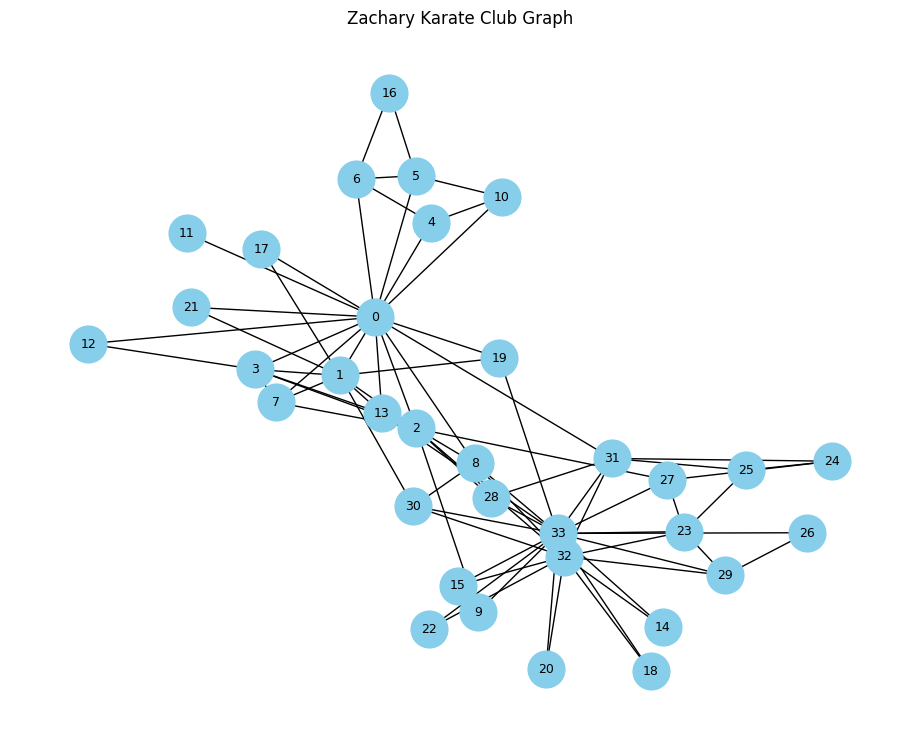

Number of nodes: 34
Number of edges: 78


In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import random
from IPython.display import display

# Load Karate Club graph
G = nx.karate_club_graph()

# Fixed layout for reproducible figures
pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(9, 7))
nx.draw(
    G,
    pos,
    with_labels=True,
    node_color="skyblue",
    node_size=700,
    font_size=9
)
plt.title("Zachary Karate Club Graph")
plt.axis("off")
plt.show()

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

## 0.1 Node Connections

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  This cell prints the adjacency list. It helps verify which members are directly connected before running any partitioning method.
</div>

[Back to dataset setup](#dataset-setup) | [Back to top](#top)


In [2]:
print("Node connections:\n")

for node in sorted(G.nodes()):
    neighbors = sorted(list(G.neighbors(node)))
    print(f"{node} is connected to {neighbors}")

Node connections:

0 is connected to [1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 17, 19, 21, 31]
1 is connected to [0, 2, 3, 7, 13, 17, 19, 21, 30]
2 is connected to [0, 1, 3, 7, 8, 9, 13, 27, 28, 32]
3 is connected to [0, 1, 2, 7, 12, 13]
4 is connected to [0, 6, 10]
5 is connected to [0, 6, 10, 16]
6 is connected to [0, 4, 5, 16]
7 is connected to [0, 1, 2, 3]
8 is connected to [0, 2, 30, 32, 33]
9 is connected to [2, 33]
10 is connected to [0, 4, 5]
11 is connected to [0]
12 is connected to [0, 3]
13 is connected to [0, 1, 2, 3, 33]
14 is connected to [32, 33]
15 is connected to [32, 33]
16 is connected to [5, 6]
17 is connected to [0, 1]
18 is connected to [32, 33]
19 is connected to [0, 1, 33]
20 is connected to [32, 33]
21 is connected to [0, 1]
22 is connected to [32, 33]
23 is connected to [25, 27, 29, 32, 33]
24 is connected to [25, 27, 31]
25 is connected to [23, 24, 31]
26 is connected to [29, 33]
27 is connected to [2, 23, 24, 33]
28 is connected to [2, 31, 33]
29 is connected

## 0.2 Real Club Groups

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  The graph contains real labels for the historical split. We use them for context and to create deliberately mixed starting partitions for KL and FM.
</div>

[Back to dataset setup](#dataset-setup) | [Back to top](#top)


In [3]:
mr_hi_nodes = sorted([
    node for node, data in G.nodes(data=True)
    if data["club"] == "Mr. Hi"
])

officer_nodes = sorted([
    node for node, data in G.nodes(data=True)
    if data["club"] == "Officer"
])

print("Mr. Hi group:", mr_hi_nodes)
print("Officer group:", officer_nodes)

print("\nMr. Hi size:", len(mr_hi_nodes))
print("Officer size:", len(officer_nodes))

Mr. Hi group: [0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 16, 17, 19, 21]
Officer group: [9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]

Mr. Hi size: 17
Officer size: 17


## 0.3 Common Helper Functions

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  These helpers keep the later algorithm sections readable: crossing edges, cut size, partition conversion, and graph drawing.
</div>

| Helper concept | Meaning |
|---|---|
| Crossing edge | An edge whose endpoints are in different partitions |
| Cut size | Number of crossing edges |
| Partition drawing | Colors nodes by partition and highlights crossing edges in red |

[Back to dataset setup](#dataset-setup) | [Back to top](#top)


In [6]:
def crossing_edges_between_two_sets(G, A, B):
    crossing = []
    for u, v in G.edges():
        if (u in A and v in B) or (u in B and v in A):
            crossing.append((u, v))
    return crossing


def cut_size_between_two_sets(G, A, B):
    return len(crossing_edges_between_two_sets(G, A, B))


def crossing_edges_from_partitions(G, partitions):
    node_to_partition = {}

    for idx, part in enumerate(partitions):
        for node in part:
            node_to_partition[node] = idx

    crossing = []

    for u, v in G.edges():
        if node_to_partition[u] != node_to_partition[v]:
            crossing.append((u, v))

    return crossing


def draw_partition(G, pos, partitions, crossing_edges, title):
    colors = [
        "skyblue", "lightgreen", "orange", "violet",
        "pink", "yellow", "lightgray", "cyan"
    ]

    node_to_partition = {}
    for idx, part in enumerate(partitions):
        for node in part:
            node_to_partition[node] = idx

    node_colors = []
    for node in G.nodes():
        part_id = node_to_partition.get(node, 0)
        node_colors.append(colors[part_id % len(colors)])

    cut_edge_set = {tuple(sorted(edge)) for edge in crossing_edges}

    normal_edges = []
    for edge in G.edges():
        if tuple(sorted(edge)) not in cut_edge_set:
            normal_edges.append(edge)

    plt.figure(figsize=(9, 7))

    nx.draw_networkx_nodes(
        G,
        pos,
        node_color=node_colors,
        node_size=700
    )

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=normal_edges,
        width=1.5,
        alpha=0.75
    )

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=crossing_edges,
        edge_color="red",
        width=2.8,
        style="dashed"
    )

    nx.draw_networkx_labels(
        G,
        pos,
        font_size=9,
        font_weight="bold"
    )

    plt.title(title)
    plt.axis("off")
    plt.show()

<a id="karger"></a>

# 1. Karger's Randomized Min-Cut Algorithm

<div style="padding:16px 20px; border-left:6px solid #dc2626; background:#fef2f2; border-radius:10px; margin:12px 0;">
  <h3 style="margin:0 0 6px 0; color:#7f1d1d;">Core idea</h3>
  <p style="margin:0; color:#374151;">Randomly contract edges until only two supernodes remain. The remaining edges between the two supernodes form a candidate global cut.</p>
</div>

| Item | Description |
|---|---|
| Partition type | Global edge min-cut |
| Why it is randomized | Different contraction choices can produce different cuts |
| Why repeated trials matter | More trials improve the chance of finding the true min-cut |
| Visualization | NetworkX exact `minimum_edge_cut` is used to show the true min-cut edges |

[Back to top](#top)


## Karger Pseudocode

```text
KARGER_MIN_CUT(G):

1. Copy graph G as a multigraph
2. While more than two supernodes remain:
      a. Randomly choose edge (u, v)
      b. Contract u and v into one supernode
      c. Remove self-loops
3. Count edges between the two remaining supernodes
4. Repeat many times
5. Return the smallest cut found
```

[Back to Karger](#karger) | [Back to top](#top)


## Karger Cell: Run Randomized Min-Cut

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  This implementation uses a `MultiGraph` so parallel edges are preserved during contraction. That detail is important for Karger's algorithm.
</div>

[Back to Karger](#karger) | [Back to top](#top)


In [7]:
import copy

def karger_min_cut_value(G):
    H = nx.MultiGraph(G)

    while H.number_of_nodes() > 2:
        u, v, key = random.choice(list(H.edges(keys=True)))
        H = nx.contracted_nodes(H, u, v, self_loops=False)

    return H.number_of_edges()


random.seed(42)

cuts = [karger_min_cut_value(G) for _ in range(200)]

print("Karger cut values from repeated runs:")
print(sorted(set(cuts)))

print("\nKarger approximate minimum cut:", min(cuts))

Karger cut values from repeated runs:
[1, 2, 3, 4, 5]

Karger approximate minimum cut: 1


## Karger Cell: Visualize a True Minimum Edge Cut

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  The red dashed edge or edges show the exact global minimum edge cut returned by NetworkX.
</div>

[Back to Karger](#karger) | [Back to top](#top)


Minimum edge cut: [(11, 0)]
Cut size: 1
Component 1: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
Component 2: [11]


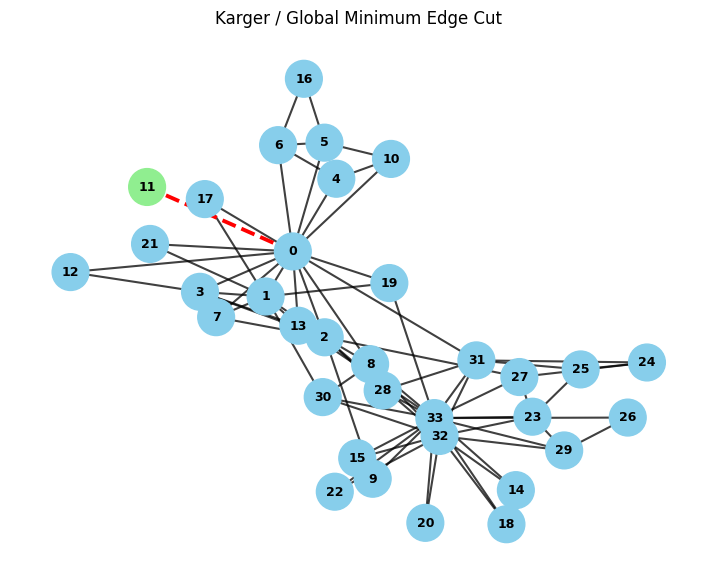

In [8]:
karger_cut_edges = list(nx.minimum_edge_cut(G))

H = G.copy()
H.remove_edges_from(karger_cut_edges)

components = [set(component) for component in nx.connected_components(H)]
components = sorted(components, key=lambda x: min(x))

print("Minimum edge cut:", karger_cut_edges)
print("Cut size:", len(karger_cut_edges))

for i, component in enumerate(components, start=1):
    print(f"Component {i}:", sorted(component))

draw_partition(
    G,
    pos,
    components,
    karger_cut_edges,
    "Karger / Global Minimum Edge Cut"
)

<a id="kl"></a>

# 2. Kernighan-Lin (KL) Algorithm

<div style="padding:16px 20px; border-left:6px solid #2563eb; background:#eff6ff; border-radius:10px; margin:12px 0;">
  <h3 style="margin:0 0 6px 0; color:#1e3a8a;">Core idea</h3>
  <p style="margin:0; color:#334155;">Start with two balanced partitions, then repeatedly swap one node from each side to reduce crossing edges.</p>
</div>

| Version | Purpose |
|---|---|
| Manual KL | Shows gain table, pair gain, locked swaps, cumulative gain, and final cut |
| NetworkX KL | Uses `nx.algorithms.community.kernighan_lin_bisection` for a tested library comparison |

**Gain formula:** `Gain(v) = External(v) - Internal(v)`  
**Pair gain formula:** `Gain(a,b) = Gain(a) + Gain(b) - 2 * edge(a,b)`

[Back to top](#top)


## KL Pseudocode

```text
KERNIGHAN_LIN(G, A, B):

1. Start with balanced partitions A and B
2. For each pass:
      a. Mark all vertices as unlocked
      b. Compute gain for unlocked vertices
      c. Score every unlocked pair (a from A, b from B)
      d. Temporarily swap the best pair and lock both nodes
      e. Track cumulative gain after each swap
3. Apply only the prefix of swaps with the best positive cumulative gain
4. Stop when no pass improves the cut
```

[Back to KL](#kl) | [Back to top](#top)


## KL Cell: Helper Functions

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Defines the bad starting partition, KL gain table, pair-gain table, crossing edges, and cut-size helpers.
</div>

[Back to KL](#kl) | [Back to top](#top)


In [9]:
def create_kl_bad_partition(mr_hi_nodes, officer_nodes):
    """
    Create a deterministic bad balanced partition for KL.

    The Karate Club graph has two real groups, but this function deliberately
    mixes nodes from both groups so KL has a poor starting point to improve.
    """
    A_kl_bad = set(mr_hi_nodes[:8] + officer_nodes[:9])
    B_kl_bad = set(mr_hi_nodes[8:] + officer_nodes[9:])

    return A_kl_bad, B_kl_bad


def kl_gain_table(G, A, B):
    rows = []

    for node in sorted(G.nodes()):
        connections = sorted(list(G.neighbors(node)))

        if node in A:
            partition = "A"
            same_partition = A
            other_partition = B
        else:
            partition = "B"
            same_partition = B
            other_partition = A

        internal = sum(1 for neighbor in connections if neighbor in same_partition)
        external = sum(1 for neighbor in connections if neighbor in other_partition)
        gain = external - internal

        rows.append({
            "Node": node,
            "Partition": partition,
            "Connections": connections,
            "External": external,
            "Internal": internal,
            "Gain": gain
        })

    return pd.DataFrame(rows)


def kl_pair_gain_table(G, A, B):
    gain_df = kl_gain_table(G, A, B)
    gain_dict = dict(zip(gain_df["Node"], gain_df["Gain"]))

    rows = []

    for a in sorted(A):
        for b in sorted(B):
            edge_between = 1 if G.has_edge(a, b) else 0
            pair_gain = gain_dict[a] + gain_dict[b] - 2 * edge_between

            rows.append({
                "Node from A": a,
                "Node from B": b,
                "Gain(A)": gain_dict[a],
                "Gain(B)": gain_dict[b],
                "Edge between them": edge_between,
                "Pair Gain": pair_gain
            })

    return pd.DataFrame(rows)


def kl_crossing_edges(G, A, B):
    return crossing_edges_between_two_sets(G, A, B)


def kl_cut_size(G, A, B):
    return cut_size_between_two_sets(G, A, B)


## KL Cell: Create the Bad Initial Partition

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Creates a balanced but deliberately mixed partition so the KL improvement process is visible.
</div>

[Back to KL](#kl) | [Back to top](#top)


KL Bad Initial Partition
A_kl_bad: [0, 1, 2, 3, 4, 5, 6, 7, 9, 14, 15, 18, 20, 22, 23, 24, 25]
B_kl_bad: [8, 10, 11, 12, 13, 16, 17, 19, 21, 26, 27, 28, 29, 30, 31, 32, 33]

Size of A_kl_bad: 17
Size of B_kl_bad: 17

KL bad partition crossing edges:
[(0, 8), (0, 10), (0, 11), (0, 12), (0, 13), (0, 17), (0, 19), (0, 21), (0, 31), (1, 13), (1, 17), (1, 19), (1, 21), (1, 30), (2, 8), (2, 13), (2, 27), (2, 28), (2, 32), (3, 12), (3, 13), (4, 10), (5, 10), (5, 16), (6, 16), (9, 33), (14, 32), (14, 33), (15, 32), (15, 33), (18, 32), (18, 33), (20, 32), (20, 33), (22, 32), (22, 33), (23, 27), (23, 29), (23, 32), (23, 33), (24, 27), (24, 31), (25, 31)]

KL bad partition cut size: 43


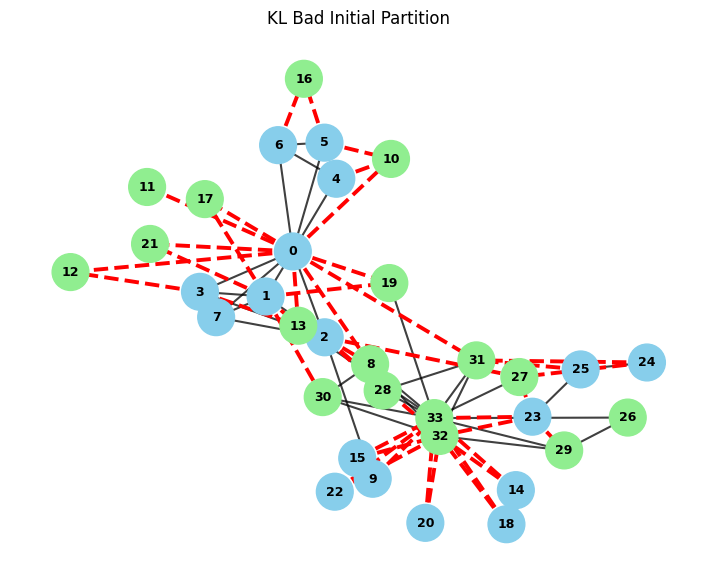

In [10]:
A_kl_bad, B_kl_bad = create_kl_bad_partition(mr_hi_nodes, officer_nodes)
kl_bad_crossing_edges = kl_crossing_edges(G, A_kl_bad, B_kl_bad)

print("KL Bad Initial Partition")
print("A_kl_bad:", sorted(A_kl_bad))
print("B_kl_bad:", sorted(B_kl_bad))

print("\nSize of A_kl_bad:", len(A_kl_bad))
print("Size of B_kl_bad:", len(B_kl_bad))

print("\nKL bad partition crossing edges:")
print(kl_bad_crossing_edges)
print("\nKL bad partition cut size:", len(kl_bad_crossing_edges))

draw_partition(
    G,
    pos,
    [A_kl_bad, B_kl_bad],
    kl_bad_crossing_edges,
    "KL Bad Initial Partition"
)


## KL Cell: Initial Gain Table

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Shows external cost, internal cost, and gain for each node before any swap.
</div>

[Back to KL](#kl) | [Back to top](#top)


In [11]:
print("Initial KL Gain Table")
display(kl_gain_table(G, A_kl_bad, B_kl_bad))


Initial KL Gain Table


,Node,Partition,Connections,External,Internal,Gain
0,0,A,"[1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 17, 1...",9,7,2
1,1,A,"[0, 2, 3, 7, 13, 17, 19, 21, 30]",5,4,1
2,2,A,"[0, 1, 3, 7, 8, 9, 13, 27, 28, 32]",5,5,0
3,3,A,"[0, 1, 2, 7, 12, 13]",2,4,-2
4,4,A,"[0, 6, 10]",1,2,-1
5,5,A,"[0, 6, 10, 16]",2,2,0
6,6,A,"[0, 4, 5, 16]",1,3,-2
7,7,A,"[0, 1, 2, 3]",0,4,-4
8,8,B,"[0, 2, 30, 32, 33]",2,3,-1
9,9,A,"[2, 33]",1,1,0


## KL Cell: Pair Gain Table

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Scores every possible cross-partition swap and sorts the best candidates first.
</div>

[Back to KL](#kl) | [Back to top](#top)


In [12]:
kl_pair_df = kl_pair_gain_table(G, A_kl_bad, B_kl_bad).sort_values(
    by="Pair Gain",
    ascending=False
).reset_index(drop=True)

print("Top KL Pair Gain Values")
display(kl_pair_df.head(15))

best_pair = kl_pair_df.iloc[0]

print("Best KL swap candidate:")
print(f"Swap {best_pair['Node from A']} with {best_pair['Node from B']}")
print("Best pair gain:", best_pair["Pair Gain"])


Top KL Pair Gain Values


,Node from A,Node from B,Gain(A),Gain(B),Edge between them,Pair Gain
0,23,10,3,3,0,6
1,23,13,3,3,0,6
2,22,13,2,3,0,5
3,22,10,2,3,0,5
4,23,17,3,2,0,5
5,23,12,3,2,0,5
6,23,21,3,2,0,5
7,23,16,3,2,0,5
8,20,10,2,3,0,5
9,20,13,2,3,0,5


Best KL swap candidate:
Swap 23 with 10
Best pair gain: 6


## KL Cell: Manual KL Function

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Runs KL pass by pass and applies only the best positive cumulative swap sequence.
</div>

[Back to KL](#kl) | [Back to top](#top)


In [13]:
def kl_manual_clean(G, A, B, max_passes=5):
    A = set(A)
    B = set(B)

    all_pass_summaries = []

    for pass_no in range(1, max_passes + 1):
        print("=" * 70)
        print(f"KL PASS {pass_no}")
        print("=" * 70)

        print("Starting A size:", len(A), "Starting B size:", len(B))
        print("Starting cut size:", kl_cut_size(G, A, B))

        A_work = set(A)
        B_work = set(B)
        locked = set()

        swap_records = []
        partition_states = []
        cumulative_gain = 0

        for step in range(min(len(A), len(B))):
            best_pair = None
            best_gain = None

            gain_df = kl_gain_table(G, A_work, B_work)
            gain_dict = dict(zip(gain_df["Node"], gain_df["Gain"]))

            for a in sorted(A_work):
                if a in locked:
                    continue

                for b in sorted(B_work):
                    if b in locked:
                        continue

                    edge_between = 1 if G.has_edge(a, b) else 0
                    pair_gain = gain_dict[a] + gain_dict[b] - 2 * edge_between

                    if best_gain is None or pair_gain > best_gain:
                        best_gain = pair_gain
                        best_pair = (a, b)

            if best_pair is None:
                break

            a, b = best_pair

            A_work.remove(a)
            B_work.remove(b)
            A_work.add(b)
            B_work.add(a)

            locked.add(a)
            locked.add(b)

            cumulative_gain += best_gain

            swap_records.append({
                "Step": step + 1,
                "Swap": f"{a} <-> {b}",
                "Pair Gain": best_gain,
                "Cumulative Gain": cumulative_gain,
                "Cut After Swap": kl_cut_size(G, A_work, B_work)
            })

            partition_states.append((set(A_work), set(B_work)))

        swap_df = pd.DataFrame(swap_records)
        print("\nKL Swap Table")
        display(swap_df)

        best_index = None
        best_cumulative_gain = 0

        for i, record in enumerate(swap_records):
            if record["Cumulative Gain"] > best_cumulative_gain:
                best_cumulative_gain = record["Cumulative Gain"]
                best_index = i

        if best_index is None:
            print("No positive improvement found. KL stops.")
            break

        A, B = partition_states[best_index]

        pass_summary = {
            "Pass": pass_no,
            "Best Cumulative Gain": best_cumulative_gain,
            "Applied Swaps": best_index + 1,
            "Cut After Pass": kl_cut_size(G, A, B)
        }
        all_pass_summaries.append(pass_summary)

        print("\nBest cumulative gain:", best_cumulative_gain)
        print("Applied first", best_index + 1, "swap(s).")
        print("Updated cut size:", kl_cut_size(G, A, B))

    print("\nFinal KL Partition")
    print("A =", sorted(A))
    print("B =", sorted(B))
    print("Final crossing edges:", kl_crossing_edges(G, A, B))
    print("Final cut size:", kl_cut_size(G, A, B))

    if all_pass_summaries:
        print("\nKL Pass Summary")
        display(pd.DataFrame(all_pass_summaries))

    return A, B


## KL Cell: Run Manual KL

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Executes the manual KL procedure on the bad starting partition.
</div>

[Back to KL](#kl) | [Back to top](#top)


In [14]:
final_A_kl, final_B_kl = kl_manual_clean(G, A_kl_bad, B_kl_bad)


KL PASS 1
Starting A size: 17 Starting B size: 17
Starting cut size: 43

KL Swap Table


,Step,Swap,Pair Gain,Cumulative Gain,Cut After Swap
0,1,23 <-> 10,6,6,37
1,2,14 <-> 13,5,11,32
2,3,15 <-> 12,4,15,28
3,4,18 <-> 16,4,19,24
4,5,20 <-> 17,4,23,20
5,6,22 <-> 21,4,27,16
6,7,24 <-> 11,2,29,14
7,8,25 <-> 19,4,33,10
8,9,9 <-> 8,-1,32,11
9,10,2 <-> 30,-2,30,13



Best cumulative gain: 33
Applied first 8 swap(s).
Updated cut size: 10
KL PASS 2
Starting A size: 17 Starting B size: 17
Starting cut size: 10

KL Swap Table


,Step,Swap,Pair Gain,Cumulative Gain,Cut After Swap
0,1,9 <-> 8,-1,-1,11
1,2,11 <-> 30,-1,-2,12
2,3,19 <-> 28,-2,-4,14
3,4,12 <-> 14,-4,-8,18
4,5,16 <-> 15,-4,-12,22
5,6,5 <-> 18,-4,-16,26
6,7,6 <-> 32,0,-16,26
7,8,4 <-> 20,-1,-17,27
8,9,10 <-> 33,2,-15,25
9,10,0 <-> 22,2,-13,23


No positive improvement found. KL stops.

Final KL Partition
A = [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 16, 17, 19, 21]
B = [8, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
Final crossing edges: [(0, 8), (0, 31), (1, 30), (2, 8), (2, 27), (2, 28), (2, 32), (9, 33), (13, 33), (19, 33)]
Final cut size: 10

KL Pass Summary


,Pass,Best Cumulative Gain,Applied Swaps,Cut After Pass
0,1,33,8,10


## KL Cell: Final Gain Table and Figure

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Displays the final manual KL partition and highlights its crossing edges.
</div>

[Back to KL](#kl) | [Back to top](#top)


Final KL Gain Table


,Node,Partition,Connections,External,Internal,Gain
0,0,A,"[1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 17, 1...",2,14,-12
1,1,A,"[0, 2, 3, 7, 13, 17, 19, 21, 30]",1,8,-7
2,2,A,"[0, 1, 3, 7, 8, 9, 13, 27, 28, 32]",4,6,-2
3,3,A,"[0, 1, 2, 7, 12, 13]",0,6,-6
4,4,A,"[0, 6, 10]",0,3,-3
5,5,A,"[0, 6, 10, 16]",0,4,-4
6,6,A,"[0, 4, 5, 16]",0,4,-4
7,7,A,"[0, 1, 2, 3]",0,4,-4
8,8,B,"[0, 2, 30, 32, 33]",2,3,-1
9,9,A,"[2, 33]",1,1,0


Final KL crossing edges: [(0, 8), (0, 31), (1, 30), (2, 8), (2, 27), (2, 28), (2, 32), (9, 33), (13, 33), (19, 33)]
Final KL cut size: 10


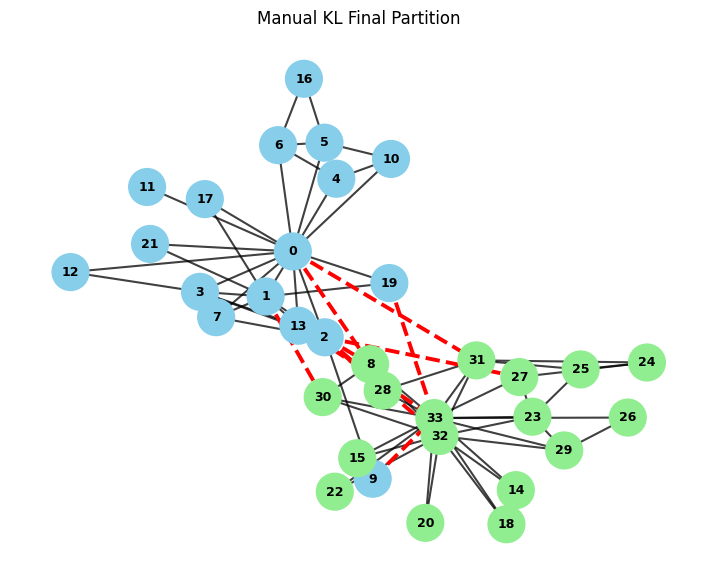

In [15]:
print("Final KL Gain Table")
display(kl_gain_table(G, final_A_kl, final_B_kl))

final_crossing_edges_kl = kl_crossing_edges(G, final_A_kl, final_B_kl)

print("Final KL crossing edges:", final_crossing_edges_kl)
print("Final KL cut size:", len(final_crossing_edges_kl))

draw_partition(
    G,
    pos,
    [final_A_kl, final_B_kl],
    final_crossing_edges_kl,
    "Manual KL Final Partition"
)


## KL Cell: Dedicated NetworkX Library Version

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Runs NetworkX KL on the same initial partition so the manual result can be compared with a library implementation.
</div>

[Back to KL](#kl) | [Back to top](#top)


In [ ]:
# Dedicated library version of KL using NetworkX

kl_library_partition = nx.algorithms.community.kernighan_lin_bisection(
    G,
    partition=(A_kl_bad, B_kl_bad),
    max_iter=10,
    seed=42
)

kl_library_A, kl_library_B = [set(part) for part in kl_library_partition]
kl_library_crossing_edges = crossing_edges_between_two_sets(G, kl_library_A, kl_library_B)

print("NetworkX KL Partition")
print("A =", sorted(kl_library_A))
print("B =", sorted(kl_library_B))
print("NetworkX KL crossing edges:", kl_library_crossing_edges)
print("NetworkX KL cut size:", len(kl_library_crossing_edges))

draw_partition(
    G,
    pos,
    [kl_library_A, kl_library_B],
    kl_library_crossing_edges,
    "NetworkX Kernighan-Lin Bisection"
)


<a id="fm"></a>

# 3. Fiduccia-Mattheyses (FM) Algorithm

<div style="padding:16px 20px; border-left:6px solid #16a34a; background:#f0fdf4; border-radius:10px; margin:12px 0;">
  <h3 style="margin:0 0 6px 0; color:#14532d;">Core idea</h3>
  <p style="margin:0; color:#334155;">FM improves the KL idea by moving one vertex at a time instead of swapping pairs.</p>
</div>

| Item | Description |
|---|---|
| Move type | Single-node move |
| Balance rule | Moves are accepted only if partition sizes stay within tolerance |
| Main table | Move, direction, gain, cumulative gain, and cut after move |
| NetworkX support | NetworkX does not provide a direct FM bisection function |

[Back to top](#top)


## FM Pseudocode

```text
FIDUCCIA_MATTHEYSES(G, A, B):

1. Start with partitions A and B
2. For each pass:
      a. Mark all vertices as unlocked
      b. Compute gain for each unlocked vertex
      c. Move the highest-gain vertex allowed by balance
      d. Lock the moved vertex
      e. Track cumulative gain after each move
3. Apply only the best balanced positive move prefix
4. Stop when no balanced improvement remains
```

[Back to FM](#fm) | [Back to top](#top)


## FM Cell: Helper Functions

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Defines FM gain, crossing edges, cut size, bad partition creation, and one-node move helpers.
</div>

[Back to FM](#fm) | [Back to top](#top)


In [16]:
def create_fm_bad_partition(mr_hi_nodes, officer_nodes):
    """
    Create a deterministic bad balanced partition for FM.

    This uses the same mixed idea as KL, but it has its own function and
    its own variables so the FM section can run independently after setup.
    """
    A_fm_bad = set(mr_hi_nodes[:8] + officer_nodes[:9])
    B_fm_bad = set(mr_hi_nodes[8:] + officer_nodes[9:])

    return A_fm_bad, B_fm_bad


def fm_gain_table(G, A, B):
    rows = []

    for node in sorted(G.nodes()):
        connections = sorted(list(G.neighbors(node)))

        if node in A:
            partition = "A"
            same_partition = A
            other_partition = B
        else:
            partition = "B"
            same_partition = B
            other_partition = A

        internal = sum(1 for neighbor in connections if neighbor in same_partition)
        external = sum(1 for neighbor in connections if neighbor in other_partition)
        gain = external - internal

        rows.append({
            "Node": node,
            "Partition": partition,
            "Connections": connections,
            "External": external,
            "Internal": internal,
            "Gain": gain
        })

    return pd.DataFrame(rows)


def fm_crossing_edges(G, A, B):
    return crossing_edges_between_two_sets(G, A, B)


def fm_cut_size(G, A, B):
    return cut_size_between_two_sets(G, A, B)


def fm_move_vertex(node, A, B):
    A = set(A)
    B = set(B)

    if node in A:
        A.remove(node)
        B.add(node)
        direction = "A -> B"
    else:
        B.remove(node)
        A.add(node)
        direction = "B -> A"

    return A, B, direction


## FM Cell: Create the Bad Initial Partition

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Creates the same kind of balanced mixed partition used to demonstrate improvement.
</div>

[Back to FM](#fm) | [Back to top](#top)


FM Bad Initial Partition
A_fm_bad: [0, 1, 2, 3, 4, 5, 6, 7, 9, 14, 15, 18, 20, 22, 23, 24, 25]
B_fm_bad: [8, 10, 11, 12, 13, 16, 17, 19, 21, 26, 27, 28, 29, 30, 31, 32, 33]

Size of A_fm_bad: 17
Size of B_fm_bad: 17

FM bad partition crossing edges:
[(0, 8), (0, 10), (0, 11), (0, 12), (0, 13), (0, 17), (0, 19), (0, 21), (0, 31), (1, 13), (1, 17), (1, 19), (1, 21), (1, 30), (2, 8), (2, 13), (2, 27), (2, 28), (2, 32), (3, 12), (3, 13), (4, 10), (5, 10), (5, 16), (6, 16), (9, 33), (14, 32), (14, 33), (15, 32), (15, 33), (18, 32), (18, 33), (20, 32), (20, 33), (22, 32), (22, 33), (23, 27), (23, 29), (23, 32), (23, 33), (24, 27), (24, 31), (25, 31)]

FM bad partition cut size: 43


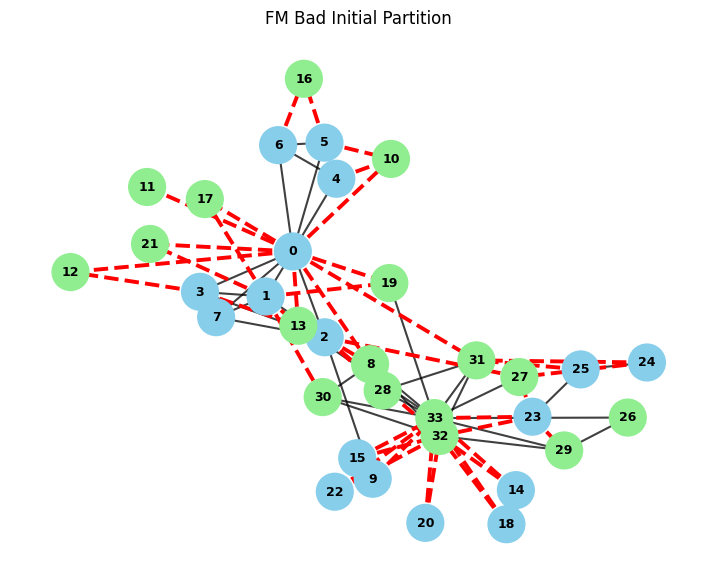

In [17]:
A_fm_bad, B_fm_bad = create_fm_bad_partition(mr_hi_nodes, officer_nodes)
fm_bad_crossing_edges = fm_crossing_edges(G, A_fm_bad, B_fm_bad)

print("FM Bad Initial Partition")
print("A_fm_bad:", sorted(A_fm_bad))
print("B_fm_bad:", sorted(B_fm_bad))

print("\nSize of A_fm_bad:", len(A_fm_bad))
print("Size of B_fm_bad:", len(B_fm_bad))

print("\nFM bad partition crossing edges:")
print(fm_bad_crossing_edges)
print("\nFM bad partition cut size:", len(fm_bad_crossing_edges))

draw_partition(
    G,
    pos,
    [A_fm_bad, B_fm_bad],
    fm_bad_crossing_edges,
    "FM Bad Initial Partition"
)


## FM Cell: Initial Gain Table

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Shows each node gain before FM starts moving nodes.
</div>

[Back to FM](#fm) | [Back to top](#top)


In [18]:
print("Initial FM Gain Table")
display(fm_gain_table(G, A_fm_bad, B_fm_bad))


Initial FM Gain Table


,Node,Partition,Connections,External,Internal,Gain
0,0,A,"[1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 17, 1...",9,7,2
1,1,A,"[0, 2, 3, 7, 13, 17, 19, 21, 30]",5,4,1
2,2,A,"[0, 1, 3, 7, 8, 9, 13, 27, 28, 32]",5,5,0
3,3,A,"[0, 1, 2, 7, 12, 13]",2,4,-2
4,4,A,"[0, 6, 10]",1,2,-1
5,5,A,"[0, 6, 10, 16]",2,2,0
6,6,A,"[0, 4, 5, 16]",1,3,-2
7,7,A,"[0, 1, 2, 3]",0,4,-4
8,8,B,"[0, 2, 30, 32, 33]",2,3,-1
9,9,A,"[2, 33]",1,1,0


## FM Cell: Manual FM Function

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Moves one node at a time, locks moved nodes, and chooses the best balanced cumulative gain.
</div>

[Back to FM](#fm) | [Back to top](#top)


In [19]:
def fm_manual_clean(G, A, B, max_passes=5, balance_tolerance=2):
    A = set(A)
    B = set(B)

    all_pass_summaries = []

    for pass_no in range(1, max_passes + 1):
        print("=" * 70)
        print(f"FM PASS {pass_no}")
        print("=" * 70)

        print("Starting A size:", len(A), "Starting B size:", len(B))
        print("Starting cut size:", fm_cut_size(G, A, B))

        A_work = set(A)
        B_work = set(B)
        locked = set()

        move_records = []
        partition_states = []
        cumulative_gain = 0

        for step in range(G.number_of_nodes()):
            best_node = None
            best_gain = None
            best_direction = None
            best_A = None
            best_B = None

            gain_df = fm_gain_table(G, A_work, B_work)
            gain_dict = dict(zip(gain_df["Node"], gain_df["Gain"]))

            for node in sorted(G.nodes()):
                if node in locked:
                    continue

                gain = gain_dict[node]
                temp_A, temp_B, direction = fm_move_vertex(node, A_work, B_work)

                # Allow small temporary imbalance.
                # A move is recorded only if it stays within this tolerance.
                if abs(len(temp_A) - len(temp_B)) > balance_tolerance:
                    continue

                if best_gain is None or gain > best_gain:
                    best_gain = gain
                    best_node = node
                    best_direction = direction
                    best_A = temp_A
                    best_B = temp_B

            if best_node is None:
                break

            A_work = best_A
            B_work = best_B
            locked.add(best_node)

            cumulative_gain += best_gain
            balanced = len(A_work) == len(B_work)

            move_records.append({
                "Step": step + 1,
                "Moved Node": best_node,
                "Direction": best_direction,
                "Gain": best_gain,
                "Cumulative Gain": cumulative_gain,
                "Cut After Move": fm_cut_size(G, A_work, B_work),
                "Balanced": balanced
            })

            partition_states.append((set(A_work), set(B_work)))

        move_df = pd.DataFrame(move_records)
        print("\nFM Move Table")
        display(move_df)

        best_index = None
        best_cumulative_gain = 0

        for i, record in enumerate(move_records):
            if record["Balanced"] and record["Cumulative Gain"] > best_cumulative_gain:
                best_cumulative_gain = record["Cumulative Gain"]
                best_index = i

        if best_index is None:
            print("No positive balanced improvement found. FM stops.")
            break

        A, B = partition_states[best_index]

        pass_summary = {
            "Pass": pass_no,
            "Best Balanced Cumulative Gain": best_cumulative_gain,
            "Applied Moves": best_index + 1,
            "Cut After Pass": fm_cut_size(G, A, B)
        }
        all_pass_summaries.append(pass_summary)

        print("\nBest balanced cumulative gain:", best_cumulative_gain)
        print("Applied first", best_index + 1, "move(s).")
        print("Updated cut size:", fm_cut_size(G, A, B))

    print("\nFinal FM Partition")
    print("A =", sorted(A))
    print("B =", sorted(B))
    print("Final crossing edges:", fm_crossing_edges(G, A, B))
    print("Final cut size:", fm_cut_size(G, A, B))

    if all_pass_summaries:
        print("\nFM Pass Summary")
        display(pd.DataFrame(all_pass_summaries))

    return A, B


## FM Cell: Run Manual FM

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Executes the manual FM improvement process.
</div>

[Back to FM](#fm) | [Back to top](#top)


In [ ]:
final_A_fm, final_B_fm = fm_manual_clean(G, A_fm_bad, B_fm_bad)


## FM Cell: Final Gain Table and Figure

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Displays and visualizes the final FM partition.
</div>

[Back to FM](#fm) | [Back to top](#top)


In [ ]:
print("Final FM Gain Table")
display(fm_gain_table(G, final_A_fm, final_B_fm))

final_crossing_edges_fm = fm_crossing_edges(G, final_A_fm, final_B_fm)

print("Final FM crossing edges:", final_crossing_edges_fm)
print("Final FM cut size:", len(final_crossing_edges_fm))

draw_partition(
    G,
    pos,
    [final_A_fm, final_B_fm],
    final_crossing_edges_fm,
    "Manual FM Final Partition"
)


<a id="metis"></a>

# 4. Multilevel Graph Partitioning / METIS

<div style="padding:16px 20px; border-left:6px solid #7c3aed; background:#f5f3ff; border-radius:10px; margin:12px 0;">
  <h3 style="margin:0 0 6px 0; color:#4c1d95;">Core idea</h3>
  <p style="margin:0; color:#334155;">Coarsen the graph, partition the smaller graph, then uncoarsen and refine the result.</p>
</div>

| Version | Purpose |
|---|---|
| Scratch educational version | Demonstrates coarsen, partition, and uncoarsen with simple Python logic |
| PyMetis library version | Uses a dedicated METIS-style multilevel partitioning library |

> NetworkX does not include METIS or a direct multilevel partitioning function.

[Back to top](#top)


## METIS Pseudocode

```text
MULTILEVEL_PARTITIONING(G, k):

1. Coarsen:
      merge strongly connected nodes into supernodes
2. Initial partition:
      split the smallest graph into k parts
3. Uncoarsen:
      map coarse partitions back to original nodes
4. Refine:
      improve boundary nodes at each level
5. Return final k partitions
```

[Back to METIS](#metis) | [Back to top](#top)


## METIS Cell: Run 2-Way Multilevel Partitioning

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Uses `pymetis` if available and explains how to install it if missing.
</div>

[Back to METIS](#metis) | [Back to top](#top)


## Multilevel Cell: Scratch Educational Version

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Shows a simplified coarsen, partition, and uncoarsen workflow for learning. It is not a replacement for METIS.
</div>

[Back to METIS](#metis) | [Back to top](#top)


In [ ]:
def greedy_coarsen_graph(G):
    unmatched = set(G.nodes())
    coarse_nodes = []

    for node in sorted(G.nodes()):
        if node not in unmatched:
            continue

        matched_neighbor = None
        for neighbor in sorted(G.neighbors(node)):
            if neighbor in unmatched:
                matched_neighbor = neighbor
                break

        if matched_neighbor is None:
            coarse_nodes.append(frozenset([node]))
            unmatched.remove(node)
        else:
            coarse_nodes.append(frozenset([node, matched_neighbor]))
            unmatched.remove(node)
            unmatched.remove(matched_neighbor)

    coarse_id = {group: idx for idx, group in enumerate(coarse_nodes)}
    fine_to_coarse = {}
    for group, idx in coarse_id.items():
        for node in group:
            fine_to_coarse[node] = idx

    coarse_G = nx.Graph()
    coarse_G.add_nodes_from(range(len(coarse_nodes)))

    for u, v in G.edges():
        cu = fine_to_coarse[u]
        cv = fine_to_coarse[v]
        if cu != cv:
            coarse_G.add_edge(cu, cv)

    return coarse_G, coarse_nodes, fine_to_coarse


def simple_balanced_partition(nodes):
    ordered = sorted(nodes)
    midpoint = len(ordered) // 2
    return set(ordered[:midpoint]), set(ordered[midpoint:])


coarse_G, coarse_groups, fine_to_coarse = greedy_coarsen_graph(G)
coarse_A, coarse_B = simple_balanced_partition(coarse_G.nodes())

manual_multilevel_A = {
    node for node in G.nodes()
    if fine_to_coarse[node] in coarse_A
}
manual_multilevel_B = set(G.nodes()) - manual_multilevel_A

manual_multilevel_crossing_edges = crossing_edges_between_two_sets(
    G,
    manual_multilevel_A,
    manual_multilevel_B
)

print("Coarse groups:")
for idx, group in enumerate(coarse_groups):
    print(f"Coarse node {idx}:", sorted(group))

print("\nScratch multilevel-style partition")
print("A =", sorted(manual_multilevel_A))
print("B =", sorted(manual_multilevel_B))
print("Crossing edges:", manual_multilevel_crossing_edges)
print("Cut size:", len(manual_multilevel_crossing_edges))

draw_partition(
    G,
    pos,
    [manual_multilevel_A, manual_multilevel_B],
    manual_multilevel_crossing_edges,
    "Scratch Multilevel-Style Partition"
)


## METIS Cell: Dedicated Library Version Using PyMetis

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Runs the dedicated PyMetis library version and reports membership, partitions, and cut size.
</div>

[Back to METIS](#metis) | [Back to top](#top)


In [ ]:
# Optional: run this line only if pymetis is missing in your environment.
# !pip install pymetis


In [ ]:
try:
    import pymetis
    pymetis_available = True
except ImportError:
    pymetis_available = False
    print("pymetis is not installed.")
    print("In Google Colab, run: !pip install pymetis")

metis_partitions = None
metis_crossing_edges = None

if pymetis_available:
    nodes = sorted(G.nodes())
    node_to_index = {node: idx for idx, node in enumerate(nodes)}

    adjacency = []
    for node in nodes:
        adjacency.append([node_to_index[neighbor] for neighbor in G.neighbors(node)])

    nparts = 2

    cuts, membership = pymetis.part_graph(nparts, adjacency=adjacency)
    membership = list(membership)

    partitions_dict = {}
    for node, part in zip(nodes, membership):
        partitions_dict.setdefault(part, []).append(node)

    metis_partitions = [set(nodes_list) for part, nodes_list in sorted(partitions_dict.items())]
    metis_crossing_edges = crossing_edges_from_partitions(G, metis_partitions)

    print("METIS membership:")
    print(membership)

    print("\nMETIS partitions:")
    for i, part in enumerate(metis_partitions):
        print(f"Partition {i}:", sorted(part))

    print("\nMETIS crossing edges:", metis_crossing_edges)
    print("METIS cut size:", len(metis_crossing_edges))
    print("METIS reported edge cuts:", cuts)

## METIS Cell: Draw METIS Result

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Draws the PyMetis result only if the dependency is installed.
</div>

[Back to METIS](#metis) | [Back to top](#top)


In [ ]:
if metis_partitions is not None:
    draw_partition(
        G,
        pos,
        metis_partitions,
        metis_crossing_edges,
        "METIS / Multilevel Graph Partitioning"
    )
else:
    print("METIS result is not available because pymetis is not installed.")

<a id="spectral"></a>

# 5. Spectral Graph Partitioning

<div style="padding:16px 20px; border-left:6px solid #0891b2; background:#ecfeff; border-radius:10px; margin:12px 0;">
  <h3 style="margin:0 0 6px 0; color:#164e63;">Core idea</h3>
  <p style="margin:0; color:#334155;">Use the graph Laplacian and the Fiedler vector to separate weakly connected groups.</p>
</div>

| Version | Purpose |
|---|---|
| Scratch NumPy version | Builds `A`, `D`, and `L`, then computes eigenvectors manually |
| NetworkX helper version | Uses `nx.linalg.algebraicconnectivity.fiedler_vector` |

**Key formula:** `L = D - A`

[Back to top](#top)


## Spectral Pseudocode

```text
SPECTRAL_PARTITIONING(G):

1. Build adjacency matrix A
2. Build degree matrix D
3. Compute Laplacian L = D - A
4. Compute eigenvalues and eigenvectors of L
5. Select the Fiedler vector
6. Split nodes by sign or threshold of Fiedler values
7. Return the two partitions
```

[Back to Spectral](#spectral) | [Back to top](#top)


## Spectral Cell: Build Matrices

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Displays the adjacency matrix, degree matrix, and Laplacian matrix.
</div>

[Back to Spectral](#spectral) | [Back to top](#top)


In [ ]:
nodes = sorted(G.nodes())

A_matrix = nx.to_numpy_array(G, nodelist=nodes)

degrees = np.sum(A_matrix, axis=1)
D_matrix = np.diag(degrees)

L_matrix = D_matrix - A_matrix

print("Adjacency Matrix A:")
display(pd.DataFrame(A_matrix.astype(int), index=nodes, columns=nodes))

print("Degree Matrix D:")
display(pd.DataFrame(D_matrix.astype(int), index=nodes, columns=nodes))

print("Laplacian Matrix L = D - A:")
display(pd.DataFrame(L_matrix.astype(int), index=nodes, columns=nodes))

## Spectral Cell: Eigenvalues and Fiedler Vector

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Computes eigenvalues/eigenvectors and extracts the second-smallest eigenvector.
</div>

[Back to Spectral](#spectral) | [Back to top](#top)


In [ ]:
eigvals, eigvecs = np.linalg.eigh(L_matrix)

eigen_df = pd.DataFrame({
    "Index": list(range(len(eigvals))),
    "Eigenvalue": eigvals
})

print("First 10 eigenvalues:")
display(eigen_df.head(10))

fiedler_vector = eigvecs[:, 1]

fiedler_df = pd.DataFrame({
    "Node": nodes,
    "Fiedler Value": fiedler_vector
})

print("Fiedler Vector Table:")
display(fiedler_df)

## Spectral Cell: Partition Using the Fiedler Vector

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Splits nodes using the sign of each Fiedler-vector value.
</div>

[Back to Spectral](#spectral) | [Back to top](#top)


In [ ]:
spectral_A = set()
spectral_B = set()

for node, value in zip(nodes, fiedler_vector):
    if value >= 0:
        spectral_A.add(node)
    else:
        spectral_B.add(node)

spectral_crossing_edges = crossing_edges_between_two_sets(G, spectral_A, spectral_B)

print("Spectral Partition A:", sorted(spectral_A))
print("Spectral Partition B:", sorted(spectral_B))

print("\nSpectral crossing edges:", spectral_crossing_edges)
print("Spectral cut size:", len(spectral_crossing_edges))

## Spectral Cell: Draw Spectral Partition

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Visualizes the spectral split and highlights crossing edges.
</div>

[Back to Spectral](#spectral) | [Back to top](#top)


In [ ]:
draw_partition(
    G,
    pos,
    [spectral_A, spectral_B],
    spectral_crossing_edges,
    "Spectral Graph Partitioning"
)

## Spectral Cell: NetworkX Fiedler-Vector Helper Version

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Uses NetworkX to compute the Fiedler vector, then applies the same sign-based split.
</div>

[Back to Spectral](#spectral) | [Back to top](#top)


In [ ]:
# Library-assisted spectral partitioning using NetworkX's Fiedler vector helper

nx_fiedler_values = nx.linalg.algebraicconnectivity.fiedler_vector(
    G,
    normalized=False,
    seed=42
)

spectral_nx_A = set()
spectral_nx_B = set()

for node, value in zip(nodes, nx_fiedler_values):
    if value >= 0:
        spectral_nx_A.add(node)
    else:
        spectral_nx_B.add(node)

spectral_nx_crossing_edges = crossing_edges_between_two_sets(G, spectral_nx_A, spectral_nx_B)

print("NetworkX Fiedler-vector spectral partition")
print("A =", sorted(spectral_nx_A))
print("B =", sorted(spectral_nx_B))
print("Crossing edges:", spectral_nx_crossing_edges)
print("Cut size:", len(spectral_nx_crossing_edges))

draw_partition(
    G,
    pos,
    [spectral_nx_A, spectral_nx_B],
    spectral_nx_crossing_edges,
    "NetworkX Fiedler-Vector Spectral Partition"
)


<a id="manual-mcl"></a>

# 6. Manual Markov Clustering Without Library

<div style="padding:16px 20px; border-left:6px solid #ea580c; background:#fff7ed; border-radius:10px; margin:12px 0;">
  <h3 style="margin:0 0 6px 0; color:#7c2d12;">Core idea</h3>
  <p style="margin:0; color:#334155;">Simulate random walks so dense communities keep probability flow inside themselves while weak links fade away.</p>
</div>

| Manual MCL operation | What it does |
|---|---|
| Self-loops | Let a random walk stay at the same node |
| Normalization | Convert adjacency values into probabilities |
| Expansion | Simulate longer random walks |
| Inflation | Strengthen high probabilities and weaken low probabilities |
| Pruning | Remove tiny transition values |
| Cluster extraction | Convert the final matrix into connected components |

[Back to top](#top)


## MCL Pseudocode

```text
MARKOV_CLUSTERING(G, r):

1. Create adjacency matrix A
2. Add self-loops
3. Normalize rows to create transition matrix M
4. Repeat until convergence:
      a. Expansion: M = M ? M
      b. Inflation: raise each value to power r
      c. Normalize rows
      d. Prune tiny values
5. Extract clusters from the final matrix
6. Return clusters
```

[Back to Manual MCL](#manual-mcl) | [Back to top](#top)


## MCL Cell: Helper Functions

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Defines row normalization, self-loop creation, expansion, inflation, and pruning.
</div>

[Back to Manual MCL](#manual-mcl) | [Back to top](#top)


In [ ]:
def normalize_rows(M):
    row_sums = M.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    return M / row_sums


def add_self_loops_matrix(G, nodes):
    A = nx.to_numpy_array(G, nodelist=nodes, dtype=float)
    np.fill_diagonal(A, 1.0)
    return A


def expand_matrix(M, power=2):
    result = M.copy()
    for _ in range(power - 1):
        result = result @ M
    return result


def inflate_matrix(M, r=1.8):
    M_power = np.power(M, r)
    return normalize_rows(M_power)


def prune_matrix(M, threshold=0.00001):
    M_pruned = M.copy()
    M_pruned[M_pruned < threshold] = 0
    return normalize_rows(M_pruned)

## MCL Cell: Initial Transition Matrix

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Builds the starting random-walk probability matrix.
</div>

[Back to Manual MCL](#manual-mcl) | [Back to top](#top)


In [ ]:
nodes = sorted(G.nodes())

A_loop = add_self_loops_matrix(G, nodes)
M_initial = normalize_rows(A_loop)

print("Initial Transition Matrix")
display(pd.DataFrame(M_initial, index=nodes, columns=nodes).round(3))

## MCL Cell: Manual MCL Function

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Runs expansion, inflation, pruning, and convergence checking.
</div>

[Back to Manual MCL](#manual-mcl) | [Back to top](#top)


In [ ]:
def manual_mcl(G, expansion_power=2, inflation_r=1.8, max_iter=100, threshold=0.00001, convergence_tol=0.000001):
    nodes = sorted(G.nodes())

    A_loop = add_self_loops_matrix(G, nodes)
    M = normalize_rows(A_loop)

    records = []

    for iteration in range(1, max_iter + 1):
        previous_M = M.copy()

        M = expand_matrix(M, power=expansion_power)
        M = inflate_matrix(M, r=inflation_r)
        M = prune_matrix(M, threshold=threshold)

        difference = np.linalg.norm(M - previous_M)

        records.append({
            "Iteration": iteration,
            "Difference": difference
        })

        if difference < convergence_tol:
            break

    return M, pd.DataFrame(records), nodes

## MCL Cell: Run Manual MCL

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Executes the manual MCL loop and displays the final matrix.
</div>

[Back to Manual MCL](#manual-mcl) | [Back to top](#top)


In [ ]:
mcl_result_matrix, mcl_iteration_df, nodes = manual_mcl(
    G,
    expansion_power=2,
    inflation_r=1.8,
    max_iter=100,
    threshold=0.00001,
    convergence_tol=0.000001
)

print("MCL Iteration Table")
display(mcl_iteration_df)

print("Final MCL Matrix")
display(pd.DataFrame(mcl_result_matrix, index=nodes, columns=nodes).round(3))

## MCL Cell: Extract Clusters

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Builds a graph from strong final probabilities and extracts connected components.
</div>

[Back to Manual MCL](#manual-mcl) | [Back to top](#top)


In [ ]:
def extract_mcl_clusters(M, nodes, threshold=0.0001):
    H = nx.Graph()
    H.add_nodes_from(nodes)

    for i, u in enumerate(nodes):
        for j, v in enumerate(nodes):
            if i != j:
                if M[i, j] > threshold or M[j, i] > threshold:
                    H.add_edge(u, v)

    clusters = [set(component) for component in nx.connected_components(H)]
    clusters = sorted(clusters, key=lambda x: min(x))

    return clusters


mcl_clusters = extract_mcl_clusters(mcl_result_matrix, nodes, threshold=0.0001)

print("Manual MCL Clusters:")
for i, cluster in enumerate(mcl_clusters, start=1):
    print(f"Cluster {i}:", sorted(cluster))

mcl_crossing_edges = crossing_edges_from_partitions(G, mcl_clusters)

print("\nMCL crossing edges:", mcl_crossing_edges)
print("MCL cut size:", len(mcl_crossing_edges))

## MCL Cell: Draw MCL Clusters

<div style="padding:12px 16px; background:#ffffff; border:1px solid #e2e8f0; border-radius:10px;">
  Visualizes the manual MCL clustering result.
</div>

[Back to Manual MCL](#manual-mcl) | [Back to top](#top)


In [ ]:
draw_partition(
    G,
    pos,
    mcl_clusters,
    mcl_crossing_edges,
    "Manual Markov Clustering Result"
)

<a id="mcl-library"></a>

# 7. Markov Clustering Using a Dedicated Library

<div style="padding:16px 20px; border-left:6px solid #f59e0b; background:#fffbeb; border-radius:10px; margin:12px 0;">
  <h3 style="margin:0 0 6px 0; color:#78350f;">Core idea</h3>
  <p style="margin:0; color:#334155;">Run MCL through the external `markov_clustering` package instead of manually coding the matrix loop.</p>
</div>

| Item | Description |
|---|---|
| Dedicated library | `markov_clustering` |
| NetworkX support | NetworkX does not include MCL directly |
| Input | Adjacency matrix from the Karate Club graph |
| Output | Cluster groups and crossing edges |

[Back to Manual MCL](#manual-mcl) | [Back to top](#top)


In [ ]:
try:
    import markov_clustering as mc
    mcl_library_available = True
except ImportError:
    mcl_library_available = False
    print("markov_clustering is not installed.")
    print("In Google Colab, run: !pip install markov_clustering")

if mcl_library_available:
    mcl_matrix = nx.to_numpy_array(G, nodelist=nodes)
    mcl_library_result = mc.run_mcl(mcl_matrix, inflation=1.8)
    mcl_library_clusters_raw = mc.get_clusters(mcl_library_result)

    mcl_library_clusters = [
        {nodes[index] for index in cluster}
        for cluster in mcl_library_clusters_raw
    ]

    mcl_library_crossing_edges = crossing_edges_from_partitions(G, mcl_library_clusters)

    print("Library MCL clusters:")
    for i, cluster in enumerate(mcl_library_clusters, start=1):
        print(f"Cluster {i}:", sorted(cluster))

    print("\nLibrary MCL crossing edges:", mcl_library_crossing_edges)
    print("Library MCL cut size:", len(mcl_library_crossing_edges))

    draw_partition(
        G,
        pos,
        mcl_library_clusters,
        mcl_library_crossing_edges,
        "Library Markov Clustering Result"
    )


<a id="final-notes"></a>

# Final Notes

<div style="padding:16px 20px; background:#f8fafc; border:1px solid #dbe3ef; border-radius:10px; margin:12px 0;">
  <h3 style="margin:0 0 8px 0; color:#0f172a;">Why results may differ</h3>
  <p style="margin:0; color:#334155;">Each algorithm optimizes a different objective, so the final partitions do not need to match exactly.</p>
</div>

| Algorithm | Main objective |
|---|---|
| Karger | Find a global minimum edge cut, even if the result is unbalanced |
| KL | Improve a balanced two-way partition through pair swaps |
| FM | Improve a balanced partition through one-node moves |
| METIS / multilevel | Efficiently find balanced partitions using coarsening and refinement |
| Spectral | Use Laplacian eigenvectors to separate weakly connected groups |
| MCL | Find dense communities using random-walk flow |

[Back to top](#top)
